# Fase 5 — Modelado

*Hábitos musicales, estado de ánimo, estrés académico y uso de IA en estudiantes de MAC, FES Acatlán*

**Objetivo.** Identificar **perfiles de estudiantes** que combinen hábitos musicales, estrés percibido y uso de IA mediante agrupamiento no supervisado (K-Means, con DBSCAN y el método jerárquico de Ward como contraste). Los perfiles se visualizan con PCA. También se evalúa formalmente si procede un modelo supervisado de "mejora de ánimo".

**Decisiones metodológicas:**

- **Datos.** Se usa el núcleo integrado (n = 19) con casos completos en las variables del modelo. No se imputan valores, por coherencia con la Fase 3.
- **Variables.** Se eligen *a priori*, con dos variables por cada bloque de la pregunta de investigación:
  - música: horas de escucha y percepción de que la música ayuda a concentrarse; además, la energía que aporta;
  - estrés: IEP;
  - IA: horas de uso y uso como guía.

  Las variables de sueño, dificultad de concentración, traslado, apoyo social y mejora de ánimo no entran al modelo. Se reservan para **validar externamente** los perfiles: si los grupos difieren en ellas sin haberlas usado, los perfiles tienen sentido sustantivo. El desánimo y la irritabilidad tampoco entran, pero no sirven como validación porque forman parte del IEP.
- **Preprocesamiento.** Las horas se transforman con `log1p` para reducir el efecto de los valores extremos (15 h de música y 8 h de IA). Todas las variables se estandarizan (z).
- **Selección de k.** Se evalúan k = 2 a 6 con el coeficiente de silueta (criterio principal; ≥ 0.25 como referencia de estructura razonable, `docs/negocio.md` §7), el índice de Davies-Bouldin y el de Calinski-Harabasz.
- **Estabilidad.** Se mide con tres contrastes: concordancia con el método de Ward, remuestreo bootstrap (ARI) y sensibilidad a la elección de variables.
- **Reproducibilidad.** La semilla es fija (`numpy.random.seed(42)` y `random_state=42`).

In [1]:
# Configuración
import sys, warnings
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import Image, display
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_score

warnings.filterwarnings("ignore")
np.random.seed(42)
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))
from datos import PROCESSED
from eda import kruskal, tabla_resultados
from modelado import (SEMILLA, distancias_k, estabilidad_bootstrap, evaluar_kmeans, explorar_dbscan, pca_2d,
                      preparar_matriz)
import graficos as gr

FIG = RAIZ / "docs" / "figuras"


def mostrar(fig, nombre, ancho=600):
    ruta = gr.guardar(fig, FIG / nombre)
    gr.plt.close(fig)
    display(Image(filename=str(ruta), width=ancho))


nucleo = pd.read_csv(PROCESSED / "integrado_123.csv")
nucleo["guia"] = (nucleo["ia_guia_vs_atajo_cod"] == "guia").astype(float).where(nucleo["ia_guia_vs_atajo_cod"].notna())
VARIABLES = ["m_horas", "m_energia_cod", "m_concentracion_cod", "iep", "ia_horas", "guia"]
ETIQ = {"m_horas": "Horas de música", "m_energia_cod": "Música → energía",
        "m_concentracion_cod": "Música → concentración", "iep": "IEP (estrés)", "ia_horas": "Horas de IA",
        "guia": "Usa IA como guía", "b_sueno_calidad_cod": "Calidad de sueño",
        "b_concentracion_dif_cod": "Dificultad de concentración", "b_desanimo_cod": "Desánimo",
        "b_irritabilidad_cod": "Irritabilidad", "b_traslado_min_cod": "Minutos de traslado",
        "b_apoyo_social_cod": "Apoyo social", "mejora_animo": "Mejora de ánimo (% sí)"}

## 1. Modelado supervisado: evaluación de viabilidad

La Fase 0 (`docs/negocio.md` §5) condicionó el modelo supervisado a que la etiqueta `mejora_animo`, derivada del texto libre del Documento 1, tuviera **al menos 4 casos en la clase minoritaria** y a que el modelo superara a la línea base.

In [2]:
# Distribución de la etiqueta y línea base
for nombre, df in [("Documento 1", pd.read_csv(PROCESSED / "doc1_musica_clean.csv")), ("Núcleo integrado", nucleo)]:
    y = df["mejora_animo"].dropna()
    base = max(y.mean(), 1 - y.mean())
    print(f"{nombre}: n = {len(y)} · mejora = {int(y.sum())} · sin cambio = {int((y == 0).sum())} "
          f"· exactitud de la línea base (predecir siempre 'mejora') = {base:.0%}")

Documento 1: n = 20 · mejora = 17 · sin cambio = 3 · exactitud de la línea base (predecir siempre 'mejora') = 85%
Núcleo integrado: n = 17 · mejora = 14 · sin cambio = 3 · exactitud de la línea base (predecir siempre 'mejora') = 82%


**Decisión: no se entrena un modelo supervisado.** La clase minoritaria tiene 3 casos, por debajo del mínimo de 4 fijado de antemano. Hay tres razones de fondo:

1. **La línea base ya acierta mucho.** Predecir siempre "mejora" logra 85 % de exactitud en el Documento 1 y 82 % en el núcleo. Un clasificador tendría que acertar los 3 casos negativos para superarla, y su F1 sobre esa clase sería inestable: cada caso mueve la métrica en tramos de un tercio.
2. **La validación cruzada estratificada no es viable.** Con 3 casos, como máximo se pueden hacer 3 particiones, y cada partición de prueba tendría un solo caso negativo. Las estimaciones de desempeño serían ruido.
3. **El EDA no encontró asociaciones robustas** con la etiqueta (Fase 4). Cualquier ajuste reflejaría sobreajuste, no señal.

Entrenar el modelo de todos modos produciría métricas engañosas. La decisión se documenta como resultado y el análisis continúa con el enfoque no supervisado, que la Fase 0 definió como primera opción.

## 2. Preparación de la matriz

In [3]:
# Casos completos, log1p en horas y estandarización
datos, Z, escalador = preparar_matriz(nucleo, VARIABLES, log=("m_horas", "ia_horas"))
print("Casos completos para el modelo:", len(datos), "de", len(nucleo))
print("Faltantes que excluyen casos:", nucleo[VARIABLES].isna().sum()[lambda s: s > 0].to_dict())
pd.DataFrame(Z, columns=VARIABLES).describe().loc[["mean", "std", "min", "max"]].round(2)

Casos completos para el modelo: 17 de 19
Faltantes que excluyen casos: {'m_concentracion_cod': 1, 'iep': 1}


,m_horas,m_energia_cod,m_concentracion_cod,iep,ia_horas,guia
mean,0.00,-0.00,0.00,-0.00,0.00,-0.00
std,1.03,1.03,1.03,1.03,1.03,1.03
min,-2.34,-2.30,-1.19,-1.47,-1.72,-0.65
max,2.20,1.10,1.19,1.59,2.50,1.55


## 3. K-Means: selección del número de perfiles

In [4]:
# Métricas internas para k = 2..6
metricas = evaluar_kmeans(Z, range(2, 7))
metricas.round(3)

,inercia,silueta,davies_bouldin,calinski_harabasz,tamaños,siluetas_negativas,ARI_vs_Ward
k,,,,,,,
2,71.807,0.259,1.283,6.307,"[12, 5]",0,1.0
3,51.714,0.280,1.208,6.807,"[6, 6, 5]",0,1.0
4,40.267,0.265,0.942,6.643,"[6, 5, 4, 2]",0,1.0
5,33.606,0.250,0.962,6.106,"[6, 4, 3, 2, 2]",0,1.0
6,27.647,0.222,0.857,5.917,"[5, 4, 3, 2, 2, 1]",0,1.0


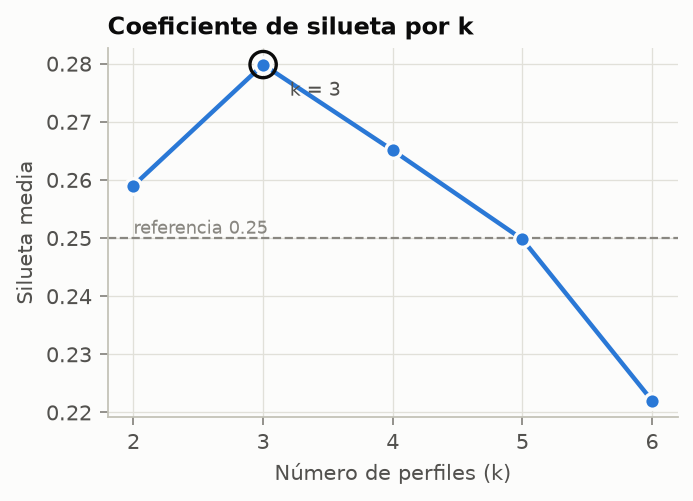

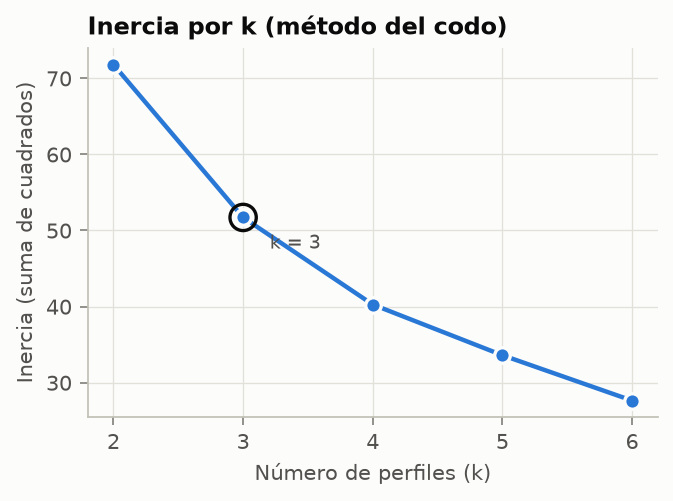

In [5]:
# Silueta por k (criterio principal) y curva del codo (inercia), en gráficas separadas
ks = list(metricas.index)
fig, ax = gr.linea_metrica(ks, metricas["silueta"].tolist(), "Coeficiente de silueta por k", "Número de perfiles (k)",
                           "Silueta media", destacar=3, referencia=0.25)
mostrar(fig, "f10_silueta_k.png", 460)
fig, ax = gr.linea_metrica(ks, metricas["inercia"].tolist(), "Inercia por k (método del codo)", "Número de perfiles (k)",
                           "Inercia (suma de cuadrados)", destacar=3)
mostrar(fig, "f11_inercia_k.png", 460)

La silueta alcanza su máximo con **k = 3** (0.28), por encima de la referencia de 0.25 y sin casos con silueta negativa. Con k = 3 la solución de K-Means coincide totalmente con la de Ward (ARI = 1.0). El codo de la inercia no es nítido, algo habitual con tan pocos casos. Se adopta **k = 3** por tener la mejor silueta y porque produce perfiles interpretables de tamaño equilibrado.

In [6]:
# Estabilidad bootstrap para k = 2, 3 y 4
estab = pd.DataFrame({k: pd.Series(estabilidad_bootstrap(Z, k, B=200)).describe(percentiles=[.1, .5])
                      for k in (2, 3, 4)}).T[["mean", "10%", "50%"]].rename(columns={"mean": "ARI_medio", "50%": "ARI_mediana", "10%": "ARI_p10"})
estab.round(2)

,ARI_medio,ARI_p10,ARI_mediana
2,0.62,-0.09,1.00
3,0.74,0.41,0.75
4,0.71,0.47,0.73


En 200 remuestras bootstrap, la solución de k = 3 conserva una concordancia **moderada** con la original: ARI medio de 0.74 y percentil 10 de 0.41. La de k = 2 tiene mediana 1.0, pero en una de cada diez remuestras se reorganiza por completo (percentil 10 negativo), así que no es más estable en conjunto. La estabilidad de k = 3 es suficiente para un análisis exploratorio, pero no permite tratar los perfiles como categorías fijas.

## 4. Perfiles resultantes

In [7]:
# Ajuste final y nombre de cada perfil según sus rasgos dominantes
km = KMeans(3, n_init=50, random_state=SEMILLA).fit(Z)
datos["perfil_id"] = km.labels_
medias = datos.groupby("perfil_id")[VARIABLES].mean()
p_musica = medias["m_horas"].idxmax()
p_estres = medias.drop(index=p_musica)["iep"].idxmax()
p_guia = ({0, 1, 2} - {p_musica, p_estres}).pop()
NOMBRES = {p_musica: "P1 · Escucha intensiva", p_estres: "P2 · Estrés alto", p_guia: "P3 · IA como guía, estrés bajo"}
datos["perfil"] = datos["perfil_id"].map(NOMBRES)
orden = [NOMBRES[p_musica], NOMBRES[p_estres], NOMBRES[p_guia]]
print("Silueta final:", round(silhouette_score(Z, km.labels_), 3))
datos["perfil"].value_counts().reindex(orden)

Silueta final: 0.28


perfil
P1 · Escucha intensiva            6
P2 · Estrés alto                  6
P3 · IA como guía, estrés bajo    5
Name: count, dtype: int64

In [8]:
# Medianas por perfil en unidades originales (variables del modelo y de validación externa)
# Desánimo e irritabilidad se excluyen de la validación: son los componentes del IEP, que está en el modelo
externas = ["b_sueno_calidad_cod", "b_concentracion_dif_cod", "b_traslado_min_cod", "b_apoyo_social_cod"]
tabla = datos.groupby("perfil")[VARIABLES + externas].median().reindex(orden).T
tabla.loc["mejora_animo"] = datos.groupby("perfil")["mejora_animo"].mean().reindex(orden)
tabla.loc["n"] = datos["perfil"].value_counts().reindex(orden)
tabla.index = [ETIQ.get(i, i) for i in tabla.index]
tabla.round(2)

perfil,P1 · Escucha intensiva,P2 · Estrés alto,"P3 · IA como guía, estrés bajo"
Horas de música,5.00,2.25,1.5
Música → energía,1.00,1.00,2.0
Música → concentración,1.00,-1.00,0.0
IEP (estrés),2.25,3.25,1.0
Horas de IA,1.50,1.25,0.5
Usa IA como guía,0.00,0.00,1.0
Calidad de sueño,1.00,1.00,1.0
Dificultad de concentración,1.00,2.00,1.0
Minutos de traslado,90.00,35.00,60.0
Apoyo social,3.00,2.00,2.0


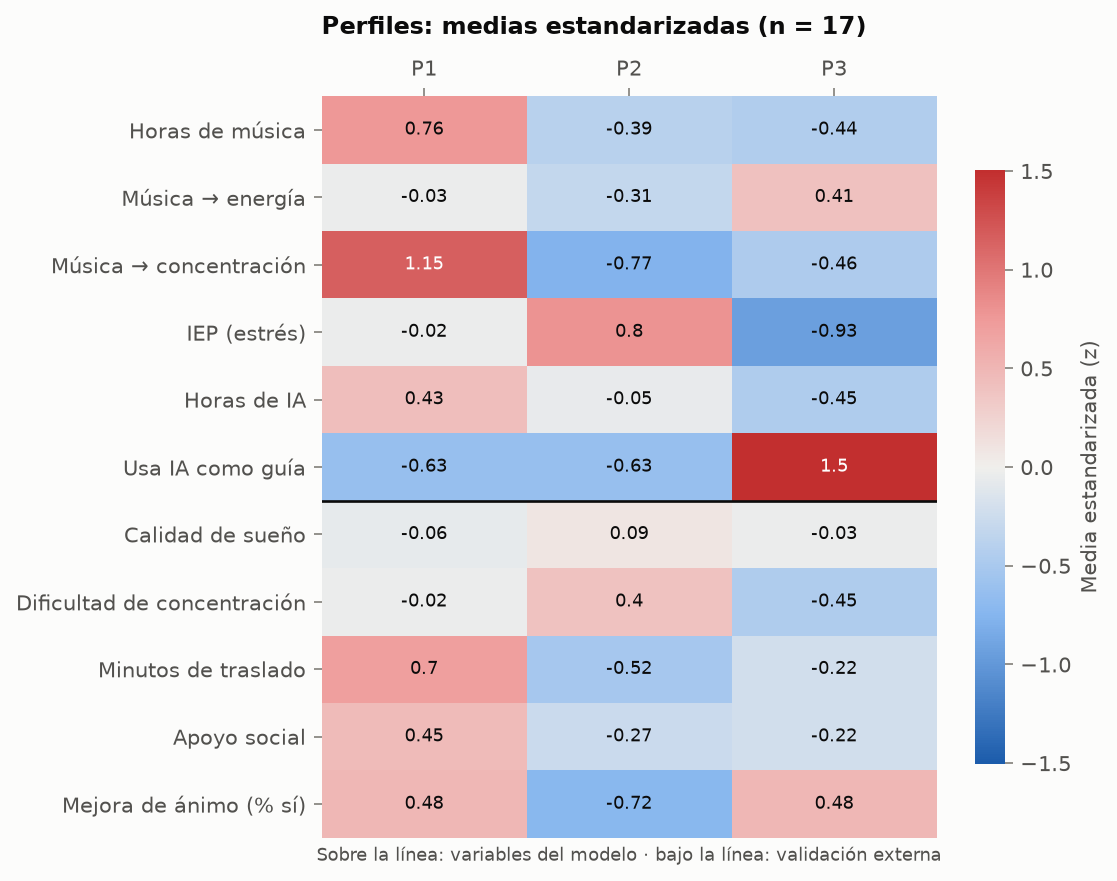

In [9]:
# Mapa de calor: medias estandarizadas por perfil (variables del modelo arriba, de validación abajo)
todas = VARIABLES + externas + ["mejora_animo"]
z = datos[todas].astype(float)
z = (z - z.mean()) / z.std()
medias_z = z.groupby(datos["perfil"]).mean().reindex(orden).T
medias_z.columns = [c.split(" · ")[0] for c in medias_z.columns]
fig, ax = gr.heatmap_perfiles(medias_z, ETIQ, "Perfiles: medias estandarizadas (n = 17)")
ax.axhline(len(VARIABLES) - 0.5, color=gr.TINTA, linewidth=1.2)
ax.set_xlabel("Sobre la línea: variables del modelo · bajo la línea: validación externa", fontsize=8, color=gr.TINTA_2)
mostrar(fig, "f12_perfiles_heatmap.png", 560)

Varianza explicada: [0.343 0.273] · acumulada: 0.615


,CP1,CP2
Horas de música,-0.40,0.53
Música → energía,0.05,0.66
Música → concentración,-0.38,0.28
IEP (estrés),-0.45,-0.03
Horas de IA,-0.34,-0.40
Usa IA como guía,0.61,0.22


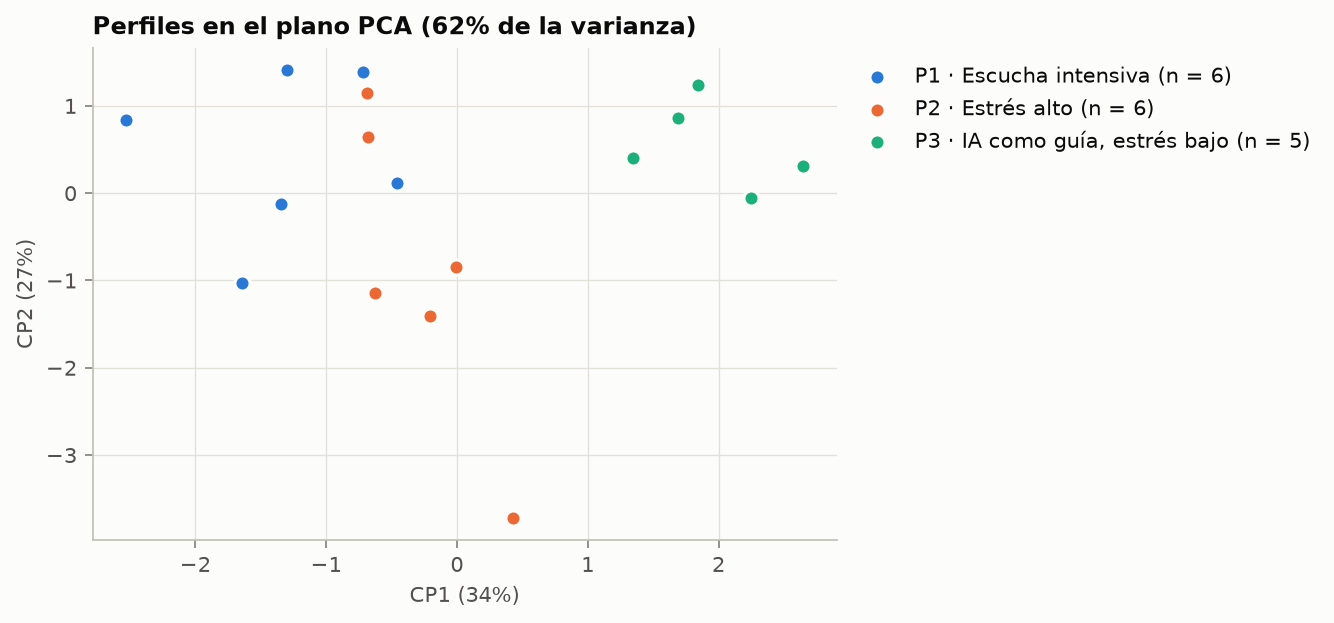

In [10]:
# PCA: proyección de los perfiles en dos componentes
proy, var_exp, cargas = pca_2d(Z, VARIABLES)
datos["CP1"], datos["CP2"] = proy[:, 0], proy[:, 1]
print("Varianza explicada:", var_exp.round(3), "· acumulada:", var_exp.sum().round(3))
display(cargas.rename(index=ETIQ).round(2))
fig, ax = gr.dispersion_por_grupo(datos, "CP1", "CP2", "perfil", orden, orden,
                                  f"Perfiles en el plano PCA ({var_exp.sum():.0%} de la varianza)",
                                  f"CP1 ({var_exp[0]:.0%})", f"CP2 ({var_exp[1]:.0%})")
for line in ax.get_lines():
    line.remove()  # en el plano PCA no se trazan rectas de tendencia
mostrar(fig, "f13_pca_perfiles.png", 620)

### 4.1 Validación externa de los perfiles

Si los perfiles capturan algo real, deberían diferir en variables que **no** se usaron para formarlos. Se aplica Kruskal-Wallis a las variables de validación. Con grupos de 5 y 6 casos, la potencia es baja; las diferencias se leen sobre todo por su tamaño de efecto (ε²).

In [11]:
# Diferencias entre perfiles en variables no usadas por el modelo
validacion = tabla_resultados([kruskal(datos, "perfil", v, "validación externa") for v in externas + ["mejora_animo"]])
validacion[["y", "n", "estadístico", "p", "q_BH", "efecto"]].rename(columns={"efecto": "ε²"})

,y,n,estadístico,p,q_BH,ε²
0,b_sueno_calidad_cod,17,0.134,0.9351,0.9351,0.008
1,b_concentracion_dif_cod,17,2.332,0.3117,0.3896,0.146
2,b_traslado_min_cod,17,9.117,0.0105,0.0524,0.570
3,b_apoyo_social_cod,17,2.756,0.2521,0.3896,0.172
4,mejora_animo,15,5.250,0.0724,0.1811,0.375


## 5. DBSCAN como contraste

DBSCAN agrupa por densidad y no exige fijar k. Para elegir `eps` se usa la gráfica de distancias al k-ésimo vecino, con `min_samples` = 3: el mínimo razonable para que un grupo tenga sentido con 17 casos.

In [12]:
# Distancias al 3er vecino y exploración de eps
dk = distancias_k(Z, 3)
print("Distancias al 3er vecino (ordenadas):", dk.round(2))
explorar_dbscan(Z, [1.6, 1.8, 2.0, 2.2, 2.5, 3.0], 3, km.labels_).round(3)

Distancias al 3er vecino (ordenadas): [1.93 2.   2.   2.   2.05 2.07 2.21 2.37 2.53 2.53 2.69 2.94 2.97 2.99
 3.03 3.14 3.25]


,grupos,ruido,tamaños,silueta_sin_ruido,ARI_vs_KMeans
eps,,,,,
1.6,0,17,[],NaN,0.000
1.8,2,10,"[3, 4]",0.435,0.229
2.0,1,8,[9],NaN,0.246
2.2,2,4,"[10, 3]",0.264,0.261
2.5,2,1,"[11, 5]",0.290,0.476
3.0,1,0,[17],NaN,0.000


DBSCAN no encuentra una estructura de densidad clara. Con `eps` ≤ 1.6 todos los casos quedan como ruido y con `eps` = 3.0 todos forman un solo grupo. En el punto intermedio más estable (`eps` = 2.5) separa un grupo de 11 y otro de 5, con un caso de ruido; esa partición coincide solo parcialmente con K-Means (ARI = 0.48). Esto es coherente con una silueta modesta: los datos no forman grupos densos y bien separados. Por eso **los perfiles de K-Means deben entenderse como una partición útil del continuo**, no como tipos naturales claramente delimitados.

## 6. Sensibilidad a la elección de variables

In [13]:
# (a) Modelo ampliado con 8 variables (incluye sueño y dificultad de concentración)
# (b) Modelo sin la variable binaria "guia"
alternativas = {
    "a) ampliado (8 variables)": VARIABLES + ["b_sueno_calidad_cod", "b_concentracion_dif_cod"],
    "b) sin 'usa IA como guía'": [v for v in VARIABLES if v != "guia"],
}
filas = []
for nombre, vars_ in alternativas.items():
    d_alt, Z_alt, _ = preparar_matriz(nucleo, vars_, log=("m_horas", "ia_horas"))
    lab = KMeans(3, n_init=50, random_state=SEMILLA).fit_predict(Z_alt)
    comunes = d_alt.index.intersection(datos.index)
    ari = adjusted_rand_score(datos.loc[comunes, "perfil_id"], pd.Series(lab, index=d_alt.index).loc[comunes])
    filas.append({"modelo": nombre, "n": len(d_alt), "silueta_k3": silhouette_score(Z_alt, lab),
                  "mejor_k": evaluar_kmeans(Z_alt, range(2, 7))["silueta"].idxmax(),
                  "silueta_mejor_k": evaluar_kmeans(Z_alt, range(2, 7))["silueta"].max(),
                  "ARI_vs_principal": ari})
pd.DataFrame(filas).set_index("modelo").round(3)

,n,silueta_k3,mejor_k,silueta_mejor_k,ARI_vs_principal
modelo,,,,,
a) ampliado (8 variables),17,0.176,2,0.191,0.385
b) sin 'usa IA como guía',17,0.201,5,0.217,0.593


Los perfiles **son sensibles a la elección de variables**:

- Con el modelo ampliado de 8 variables, la estructura se debilita (silueta de 0.18 con k = 3) y la partición coincide poco con la principal (ARI = 0.39).
- Sin la variable "usa IA como guía", la silueta baja a 0.20 y la coincidencia es moderada (ARI = 0.59).

Esto confirma que la modalidad de uso de IA es un eje importante de la separación, y que la estructura de grupos en estos datos es **débil**. Solo el conjunto parsimonioso, elegido *a priori*, supera la referencia de 0.25. Los perfiles son una herramienta descriptiva útil para el tablero, no una tipología robusta de la población.

## 7. Guardado de las asignaciones

Las asignaciones de perfil (seudónimo, perfil y coordenadas PCA) se guardan en `data/processed/perfiles.csv` para que el tablero las use en la Fase 6. Los 2 estudiantes del núcleo con datos incompletos no reciben perfil.

In [14]:
# Guardado de perfiles (sin identificadores reales)
salida = datos[["id", "perfil", "CP1", "CP2"]]
salida.to_csv(PROCESSED / "perfiles.csv", index=False, encoding="utf-8")
print("perfiles.csv:", salida.shape, "| perfiles:", salida["perfil"].value_counts().to_dict())

perfiles.csv: (17, 4) | perfiles: {'P2 · Estrés alto': 6, 'P1 · Escucha intensiva': 6, 'P3 · IA como guía, estrés bajo': 5}


## 8. Conclusiones de la fase

**Perfiles identificados** (K-Means con k = 3, n = 17, silueta de 0.28):

| Perfil | n | Rasgos que lo definen | Validación externa |
|--------|--:|-----------------------|--------------------|
| **P1 · Escucha intensiva** | 6 | Más horas de música (mediana 5 h), percibe que la música le ayuda a concentrarse, estrés medio (IEP 2.25), usa la IA como guía y atajo | Traslados más largos (mediana 90 min) y mejora de ánimo en el 100 % |
| **P2 · Estrés alto** | 6 | Estrés alto (IEP 3.25), menos horas de música (2.25 h), percibe que la música lo distrae al estudiar, usa la IA como guía y atajo | Traslados más cortos (35 min), más dificultad de concentración y mejora de ánimo solo en el 50 % |
| **P3 · IA como guía, estrés bajo** | 5 | Usa la IA como guía para aprender, con pocas horas de IA (0.5 h) y de música (1.5 h), y estrés bajo (IEP 1.0); la música le da energía | Mejora de ánimo en el 100 % |

**Lectura sustantiva.** Los perfiles reproducen las señales de la Fase 4:

- el estrés bajo se concentra en quienes usan la IA como guía para aprender;
- el perfil de estrés alto es también el que menos se beneficia de la música: la percibe como distractora y solo la mitad reporta mejora de ánimo;
- la escucha intensiva acompaña traslados largos y se asocia con percibir beneficios funcionales, como concentrarse y mejorar el ánimo, sin que eso se traduzca en un estrés menor que el promedio.

**Calidad del modelo:**

| Criterio | Resultado |
|----------|-----------|
| Silueta | 0.28, por encima de la referencia de 0.25, sin casos negativos |
| Concordancia con Ward | Total (ARI = 1.0) |
| Estabilidad bootstrap | Moderada (ARI medio de 0.74) |
| Validación externa | La diferencia más clara está en los minutos de traslado (ε² = 0.57; *p* = 0.011, *q* > 0.05). La mejora de ánimo también difiere de forma apreciable (ε² = 0.38). Sueño y apoyo social no difieren |
| DBSCAN | No confirma grupos densos |
| Sensibilidad a las variables | Alta |

**Modelo supervisado.** No se entrenó porque la etiqueta `mejora_animo` no alcanza el mínimo de 4 casos en la clase minoritaria (tiene 3). La línea base ya logra 82 a 85 % de exactitud.

**Limitaciones.**

- n = 17 en el modelo.
- La estructura de grupos es débil y sensible a las variables elegidas.
- Una variable binaria pesa mucho en la estandarización.
- Los datos son auto-reportados.
- Los perfiles describen asociaciones y no implican que cambiar un hábito cambie el estado de ánimo.

